In [1]:
import numpy as np
import torch

#Loading reference posterior parameters
with np.load("radial_reference.npz") as data:
    observed = data["observed"].copy()
    uncertainty = data["uncertainty"].copy()
    usable = data["usable"].copy()
    theta_true = data["theta_true"].copy()

    #Prior constrains
    prior_low = data["prior_low"].copy()
    prior_high = data["prior_high"].copy()

# Simulate data

In [2]:
from cosmology import Cosmology
from lensing import simulate_map
from compression import project_shear, radial_compression

# Load the exact observing setup used for the reference posterior.
with np.load("radial_reference.npz") as data:
    observed = data["observed"].copy()
    usable = data["usable"].copy()
    theta_true = data["theta_true"].copy()

    prior_low = data["prior_low"].copy()
    prior_high = data["prior_high"].copy()

    x = data["x"].copy()
    y = data["y"].copy()
    bin_edges = data["bin_edges"].copy()

    pixel_mask = data["pixel_valid"].copy()
    count_map = data["count_map"].copy()
    sigma_galaxy = float(data["sigma_galaxy"])

    true_centre = data["true_centre"].copy()
    assumed_centre = data["assumed_centre"].copy()
    z_lens = float(data["z_lens"])
    z_source = float(data["z_source"])

    cosmology = Cosmology(
        H0=float(data["H0"]),
        Omega_m=float(data["Omega_m"]),
        Omega_lambda=float(data["Omega_lambda"]),
    )

Sigma_crit = cosmology.critical_surface_density(z_lens, z_source)

# The held-out observation used to condition the SBI posterior.
observed_radial = torch.as_tensor(
    observed[usable], dtype=torch.float32
)
true_parameters = theta_true

def simulate_radial(theta):
    # Generate a noisy map for this parameter pair.
    g_obs_map, _, pixel_sigma, pixel_valid = simulate_map(
        theta=theta,
        x=x,
        y=y,
        centre=true_centre,
        mask=pixel_mask,
        z_l=z_lens,
        Sigma_crit=Sigma_crit,
        cosmology=cosmology,
        N_per_pixel=count_map,
        sigma_galaxy=sigma_galaxy,
    )

    # Obtain the quantities needed for compression.
    radius, angle, gt, gx = project_shear(
        g_obs_map, x, y, assumed_centre
    )

    radial_result = radial_compression(
        gt, radius, pixel_sigma, pixel_valid, bin_edges
    )

    assert np.all(radial_result.valid[usable])

    result = torch.as_tensor(
        radial_result.shear[usable],
        dtype=torch.float32,
    )
    assert torch.isfinite(result).all()

    return result


# Call the function to generate one example.
training_radial = simulate_radial(true_parameters)

print(training_radial.shape)
assert training_radial.shape == observed_radial.shape



torch.Size([15])


## Repeat and build the training set

In [ ]:
from sbi.utils import BoxUniform
prior = BoxUniform(low = torch.as_tensor(prior_low, dtype=torch.float32),
                   high = torch.as_tensor(prior_high,dtype=torch.float32),)
num_simulations = 1000
theta_train = prior.sample((num_simulations,))

x_train = torch.stack(
    [simulate_radial(theta_i) for theta_i in theta_train],
    dim=0,
)

#Check
print("theta.shape",theta_train.shape)  # torch.Size([num_simulations, 2])
print("x.shape",x_train.shape)      # torch.Size([num_simulations, 15])

assert x_train.shape[1:] == observed_radial.shape
assert torch.isfinite(x_train).all()


theta.shape torch.Size([1000, 2])
x.shape torch.Size([1000, 15])
torch.Size([15])


# Training the neural network

 Neural network successfully converged after 240 epochs.

  0%|          | 0/5000 [00:00<?, ?it/s]

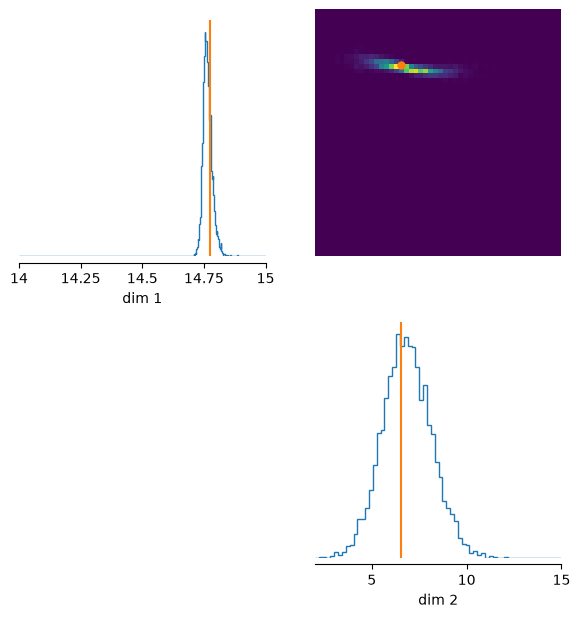

In [8]:
from sbi.inference import NPE
from sbi.analysis import pairplot

inference = NPE(prior=prior)
density_estimator = inference.append_simulations(
    theta_train, x_train
).train()
posterior = inference.build_posterior(density_estimator)

posterior_samples = posterior.sample((5000,), x = observed_radial)

_ = pairplot(
    samples=posterior_samples,
    points=torch.as_tensor(theta_true, dtype=torch.float32)[None, :],  # `points` needs a batch dimension.
    limits=[[14.0, 15.0], [2.0, 15.0]],
    figsize=(7, 7),
)

# Infer the neural network

## Validating the network


SBI
Mean: [14.764083  6.843072]
Standard deviation: [0.01853166 1.2843072 ]
16%, 50%, 84%: [[14.7472134   5.5780549 ]
 [14.76184273  6.81216478]
 [14.78122219  8.11727982]]
Correlation: -0.7299147703194381

Grid
Mean: [14.75917559  6.77894783]
Standard deviation: [0.01320524 0.90787461]
16%, 50%, 84%: [[14.7458194   5.89130435]
 [14.75919732  6.7173913 ]
 [14.77257525  7.65217391]]
Correlation: -0.6224825331947381


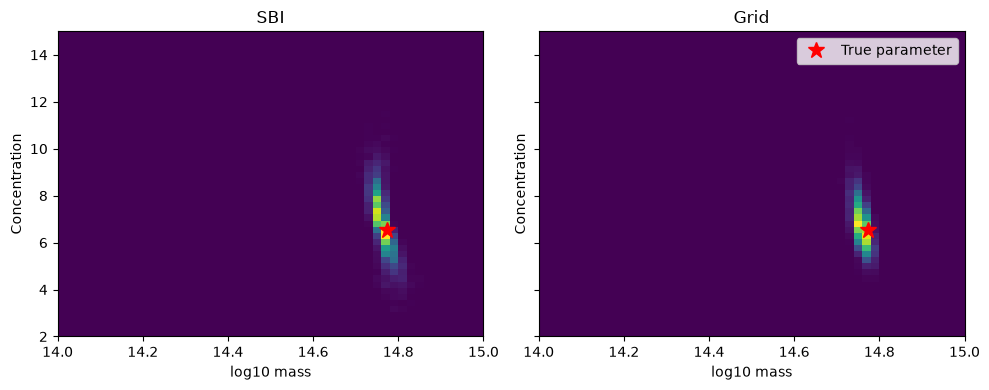

In [ ]:
import matplotlib.pyplot as plt

with np.load("radial_reference.npz") as data:
    grid_probability = data["posterior"].copy()
    mass_grid = data["log_mass_grid"].copy()
    concentration_grid = data["concentration_grid"].copy()

sbi_samples = posterior_samples.detach().cpu().numpy()

# Draw parameter pairs from the saved grid probabilities.
weights = grid_probability.ravel()
weights = weights / weights.sum()

rng = np.random.default_rng(42)
flat_indices = rng.choice(
    weights.size, size=len(sbi_samples), p=weights
)
mass_indices, concentration_indices = np.unravel_index(
    flat_indices, grid_probability.shape
)

grid_samples = np.column_stack((
    mass_grid[mass_indices],
    concentration_grid[concentration_indices],
))

# Compare centre, spread, and mass–concentration correlation.
for name, samples in [
    ("SBI", sbi_samples),
    ("Grid", grid_samples),
]:
    print(f"\n{name}")
    print("Mean:", samples.mean(axis=0))
    print("Standard deviation:", samples.std(axis=0))
    print("16%, 50%, 84%:", np.quantile(
        samples, [0.16, 0.50, 0.84], axis=0
    ))
    print("Correlation:", np.corrcoef(samples.T)[0, 1])

# Compare their shapes using identical axes.
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)

for ax, name, samples in zip(
    axes, ["SBI", "Grid"], [sbi_samples, grid_samples]
):
    ax.hist2d(
        samples[:, 0], samples[:, 1],
        bins=50,
        range=[[14, 15], [2, 15]],
    )
    ax.plot(theta_true[0], theta_true[1], "r*", markersize=12, label = "True parameter")
    ax.set(
        title=name,
        xlabel="log10 mass",
        ylabel="Concentration",
    )
ax.legend()
plt.tight_layout()
plt.show()

### Posterior predictive check

torch.Size([100, 15])
Median: tensor([-0.0054,  0.0023,  0.0055,  0.0098,  0.0187,  0.0287,  0.0382,  0.0356,
         0.0320,  0.0275,  0.0231,  0.0195,  0.0162,  0.0130,  0.0105])
16th percentile: tensor([-0.0116, -0.0030,  0.0002,  0.0049,  0.0153,  0.0259,  0.0350,  0.0336,
         0.0300,  0.0258,  0.0216,  0.0183,  0.0151,  0.0122,  0.0099])
84th percentile: tensor([0.0011, 0.0079, 0.0091, 0.0141, 0.0219, 0.0316, 0.0413, 0.0379, 0.0344,
        0.0290, 0.0244, 0.0203, 0.0172, 0.0140, 0.0113])


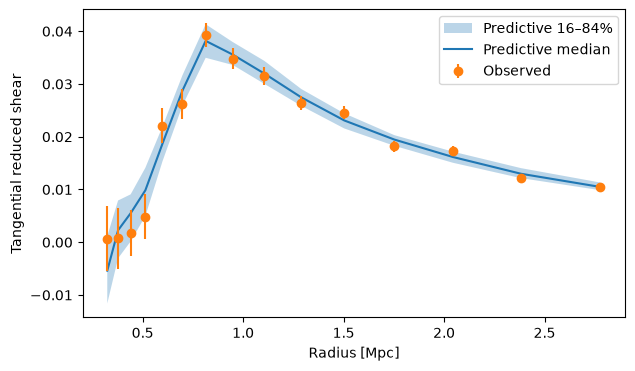

In [18]:
posterior_check = posterior_samples[:100]
predictive_check = torch.stack([
    simulate_radial(theta) for theta in posterior_check
])
print(predictive_check.shape)  # (100, 15)

median = torch.quantile(predictive_check, 0.5, dim=0)
p16 = torch.quantile(predictive_check, 0.16, dim=0)
p84 = torch.quantile(predictive_check, 0.84, dim=0)

print("Median:", median)
print("16th percentile:", p16)
print("84th percentile:", p84)

# Plot against the centres of the usable radial bins.
radii = np.sqrt(bin_edges[:-1] * bin_edges[1:])[usable]

plt.figure(figsize=(7, 4))
plt.fill_between(radii, p16.numpy(), p84.numpy(),
                 alpha=0.3, label="Predictive 16–84%")
plt.plot(radii, median.numpy(), label="Predictive median")
plt.errorbar(
    radii, observed_radial.numpy(),
    yerr=uncertainty[usable],
    fmt="o", label="Observed",
)
plt.xlabel("Radius [Mpc]")
plt.ylabel("Tangential reduced shear")
plt.legend()
plt.show()
